In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

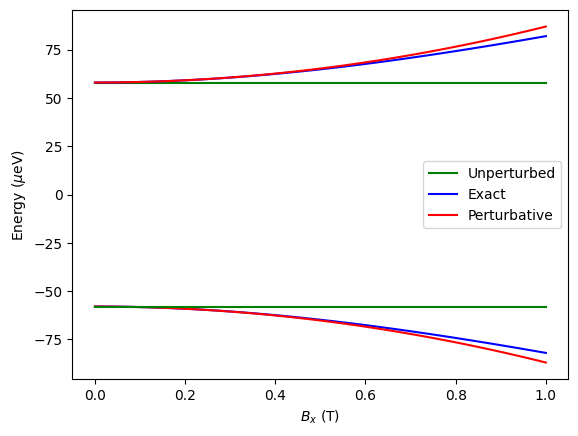

In [4]:
B0 = 1 # 1 Tesla
muB = 58 # Bohr magneton in mueV/T
g = 2
H_0 = g*muB* B0 * np.array([[1, 0], [0, -1]], dtype=complex) / 2
E0 = np.linalg.eigvalsh(H_0)

B1 = np.linspace(0, 1, 100)
perturbed_spectrum = np.zeros((2,100))
exact_spectrum = np.zeros((2,100))
for k in range(100):
    H_1 = g*muB* B1[k] * np.array([[0, 1], [1, 0]], dtype=complex) / 2
    exact_spectrum[:,k] = np.linalg.eigvalsh(H_0 + H_1)
    perturbed_spectrum[:,k] = E0 + np.array([-1,1])*g*muB*B1[k]**2/B0 / 4

plt.plot(B1, np.ones(100)*g*muB*B0/2, color='green', label='Unperturbed')
plt.plot(B1, exact_spectrum[0, :], color='blue', label='Exact')
plt.plot(B1, perturbed_spectrum[0, :], color='red', label='Perturbative')
plt.plot(B1, -np.ones(100)*g*muB*B0/2, color='green')
plt.plot(B1, exact_spectrum[1, :], color='blue')
plt.plot(B1, perturbed_spectrum[1, :], color='red')

plt.xlabel('$B_x$ (T)')
plt.ylabel('Energy ($\\mu$eV)')
plt.legend()
plt.show()
